# FDFD: Maxwell's equations one frequency at a time

The FDTD notebooks ([57](57_fdtd_basics.ipynb) to
[64](64_fdtd_3d_nanojet.ipynb)) step the fields through time. The
**finite-difference frequency-domain** method (FDFD) solves the same
equations on the same Yee grid at a single frequency instead, as one
sparse linear system:

* a **driven problem** (a source at a wavelength) is one sparse LU solve,
* the **resonances** of an open structure, complex frequencies
  $\omega$ with $\operatorname{Im}\omega < 0$, their $Q$ and their
  fields, are the eigenvalues of the same operator near a guess. High
  $Q$ costs nothing extra, while an FDTD run would have to ring down for
  $Q$ periods,
* media enter with their complex permittivity at the wavelength, so lossy
  and dispersive materials need no fit.

This notebook introduces `pyoptics.fdfd` and checks it against exact
results:

1. the operator and the cell,
2. a plane wave on a dielectric cylinder, in both polarizations, against
   the exact series,
3. the resonances of a microdisk against the exact whispering gallery
   modes,
4. far fields from cylindrical waves.

Notebook [67](67_fdfd_limacon_microcavity.ipynb) applies it to a deformed
microdisk, the limaçon of Pascal. Lengths are in units of the vacuum
wavelength unless stated.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import analytical as an
from pyoptics import fdfd, fdtd
from pyoptics.fdtd import plot as fplot

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
t_start = time.perf_counter()


def box(ax, b, **kw):
    # the total-field box of a PlaneWave source
    (x0, x1), (y0, y1) = b
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#e0a000", ls="--", lw=1.2, **kw))

## 1. The operator and the cell

In 2D the fields split into the two polarizations of the FDTD: **Ez**
(E along z, with Hx, Hy) and **Hz** (H along z, with Ex, Ey). With the
time dependence $e^{-i\omega t}$ and $c = 1$, the field $u$ along z obeys

$$\text{Ez:}\quad \partial_x\partial_x u + \partial_y\partial_y u + \omega^2\varepsilon\,u = -i\omega J_z,
\qquad
\text{Hz:}\quad \partial_x\frac{1}{\varepsilon_y}\partial_x u + \partial_y\frac{1}{\varepsilon_x}\partial_y u + \omega^2 u = -i\omega M_z .$$

Each derivative is a difference between two neighbours of the Yee cell;
in the **PML** the coordinates are stretched,
$\partial_x \to \frac{1}{s_x}\partial_x$ with
$s_x = \kappa + i\sigma(x)/\omega$, which turns outgoing waves into
decaying ones. The result is a sparse matrix with five diagonals,
$A u = b$. A plane wave enters through the edge of a **total-field box**:
inside it the solution is the total field, outside only the scattered
field. The incident wave uses the wave number of the grid, so the box
does not leak.

The cell of the scattering problem of section 2: a glass rod
(n = 1.8, radius 0.6 λ), the total-field box (amber), the PML (hatched);
on the right the pattern of the matrix for a small grid.

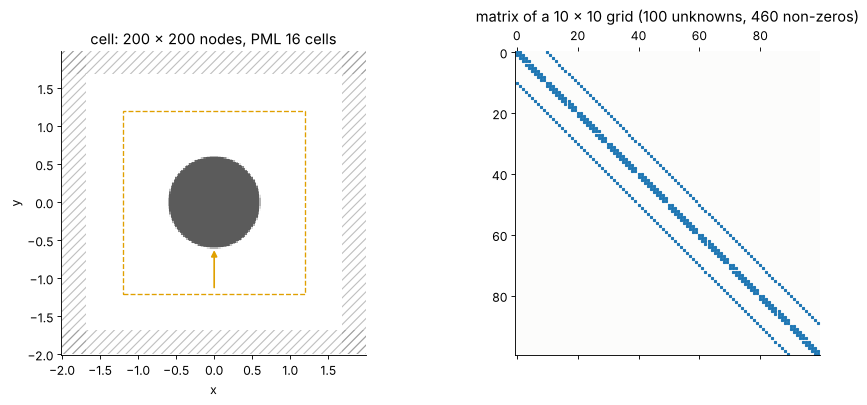

In [2]:
R_cyl, n_cyl = 0.6, 1.8
tf_box = ((-1.2, 1.2), (-1.2, 1.2))
sim = fdfd.Simulation(fdtd.Grid((4.0, 4.0), 0.02), [(fdtd.Circle((0, 0), R_cyl), fdtd.Medium.from_index(n_cyl))])
small = fdfd.Simulation(fdtd.Grid((0.3, 0.3), 0.03), [(fdtd.Circle((0, 0), 0.1), fdtd.Medium.from_index(n_cyl))],
                        boundaries=("pec", "pec"))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
fplot.plot_structure(sim, ax=axes[0])
box(axes[0], tf_box)
axes[0].annotate("", xy=(0, -0.6), xytext=(0, -1.15), arrowprops=dict(arrowstyle="-|>", color="#e0a000", lw=1.5))
axes[0].set_title(f"cell: {sim.grid.shape[0]} x {sim.grid.shape[1]} nodes, PML 16 cells")
A = small.operator(1.0)
axes[1].spy(A, markersize=2)
axes[1].set_title(f"matrix of a 10 x 10 grid ({A.shape[0]} unknowns, {A.nnz} non-zeros)")
plt.tight_layout()

## 2. A plane wave on a dielectric cylinder

The plane wave travels along +y. The exact solution is the series of
`analytical.cylinder_field`, now in both polarizations
(`polarization="E"` for E along the axis, `"H"` for H along it). The
cylinder is drawn first, then the fields with its outline, and the error
of the FDFD inside the box.

1.1 s for both solves (40000 unknowns each)


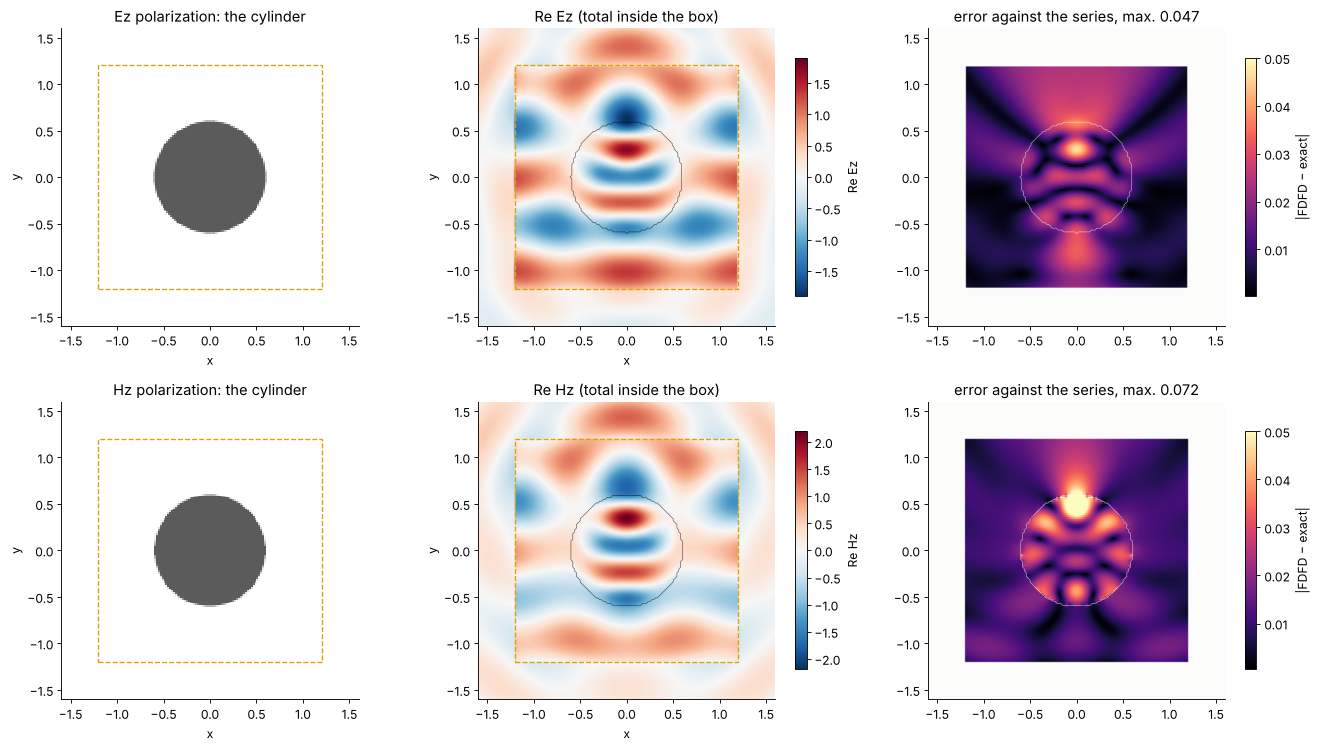

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
t0 = time.perf_counter()
for row, (mode, pol) in zip(axes, (("Ez", "E"), ("Hz", "H"))):
    s = fdfd.Simulation(sim.grid, sim.structure, mode=mode)
    sol = s.solve(1.0, fdfd.PlaneWave((0, 1), tf_box))
    x, y = sol.coords[mode]
    X, Y = np.meshgrid(x, y, indexing="ij")
    exact = an.cylinder_field(X, Y, R_cyl, n_cyl, 1.0, polarization=pol)
    fplot.plot_structure(s, ax=row[0], show_pml=False)
    box(row[0], tf_box)
    row[0].set_title(f"{mode} polarization: the cylinder")
    fplot.plot_field(sol, mode, ax=row[1], sim=s, part="real", title=f"Re {mode} (total inside the box)")
    box(row[1], tf_box)
    err = np.where((np.abs(X) < 1.2) & (np.abs(Y) < 1.2), np.abs(sol.main - exact), np.nan)
    im = row[2].imshow(err.T, origin="lower", extent=fplot._extent((x, y)), cmap="magma", vmax=0.05)
    fplot._structure_outline(row[2], s, color="w")
    plt.colorbar(im, ax=row[2], shrink=0.8, label="|FDFD − exact|")
    row[2].set_title(f"error against the series, max. {np.nanmax(err):.3f}")
    for ax in row:
        ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
print(f"{time.perf_counter() - t0:.1f} s for both solves ({sim.grid.shape[0]*sim.grid.shape[1]} unknowns each)")
plt.tight_layout()

The error sits at the surface of the rod, where the staircase of the
grid is averaged (arithmetically for E along z, anisotropically for the
in-plane E of the Hz mode), and in the phase, which drifts with the
dispersion of the grid. Both fall as $h^2$:

Ez seconds per solve: [0.04 0.07 0.17 0.36 0.96 3.73]


Hz seconds per solve: [0.04 0.07 0.14 0.39 0.84 3.26]


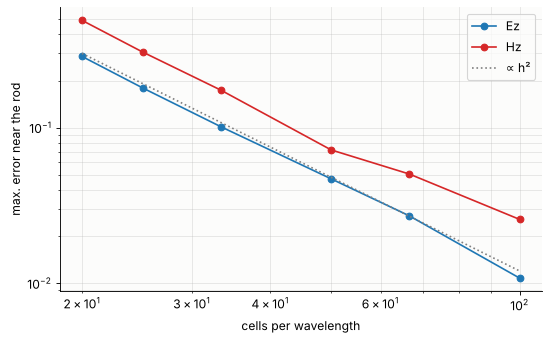

In [4]:
hs = np.array([0.05, 0.04, 0.03, 0.02, 0.015, 0.01])
fig, ax = plt.subplots(figsize=(7, 4.4))
for mode, pol, c in (("Ez", "E", "C0"), ("Hz", "H", "C3")):
    err, cost = [], []
    for h in hs:
        s = fdfd.Simulation(fdtd.Grid((4.0, 4.0), h), sim.structure, mode=mode)
        t1 = time.perf_counter()
        sol = s.solve(1.0, fdfd.PlaneWave((0, 1), tf_box))
        cost.append(time.perf_counter() - t1)
        x, y = sol.coords[mode]
        X, Y = np.meshgrid(x, y, indexing="ij")
        sel = (np.abs(X) < 1.1) & (np.abs(Y) < 1.1)
        err.append(np.abs(sol.main - an.cylinder_field(X, Y, R_cyl, n_cyl, 1.0, polarization=pol))[sel].max())
    ax.loglog(1/hs, err, "o-", color=c, label=f"{mode}")
    print(mode, "seconds per solve:", np.round(cost, 2))
ax.loglog(1/hs, 0.3*(hs/0.05)**2, ":", color="gray", label="∝ h²")
ax.set_xlabel("cells per wavelength"); ax.set_ylabel("max. error near the rod")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout()

## 3. Resonances of a microdisk

A disk of index 3.3 (GaAs) and radius R traps light in **whispering
gallery modes** (WGM): waves running around the rim by total internal
reflection, $u \propto J_m(n k r)\,e^{\pm i m\varphi}$ inside. They leak
out by tunnelling through the curved boundary, so their Q grows
exponentially with the azimuthal number m. The exact resonances solve the
matching condition of the Bessel and Hankel functions at r = R
(`analytical.disk_resonance`).

`Simulation.resonances(wavelength, n)` returns the n modes whose
eigenvalues $-\omega^2$ lie nearest to the guess (shift-invert Arnoldi).
The disk (radius 1, in units of R) with its cell first, then all modes in
a band against the exact ones:

10 s


/usr/local/lib/python3.13/site-packages/scipy/special/_basic.py:814: RuntimeWarning: invalid value encountered in scalar multiply
  s += p*L(v-n + i*2, z)
/home/claude/pyoptics/pyoptics/analytical.py:350: RuntimeWarning: invalid value encountered in scalar divide
  return g*jvp(m, m_rel*x)/jv(m, m_rel*x) - h1vp(m, x)/hankel1(m, x)
/usr/local/lib/python3.13/site-packages/scipy/optimize/_zeros_py.py:394: RuntimeWarning: invalid value encountered in scalar divide
  p = (-q1 / q0 * p0 + p1) / (1 - q1 / q0)


Ez: 36 FDFD modes matched to exact ones, wavelength within 1.6e-03, Q within 0.9 %
Hz: 36 FDFD modes matched to exact ones, wavelength within 2.2e-03, Q within 4.7 %


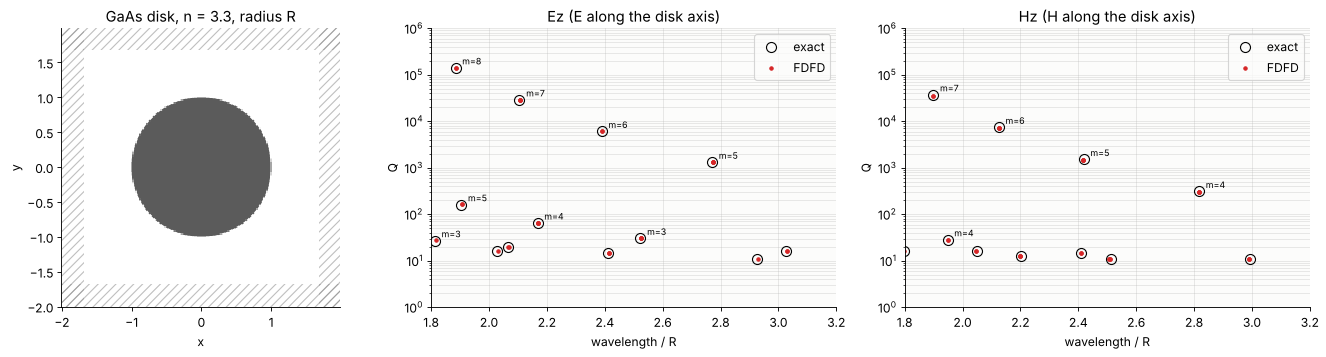

In [5]:
R, n_d = 1.0, 3.3
gaas = fdtd.Medium.from_index(n_d)
disk = fdfd.Simulation(fdtd.Grid((4.0, 4.0), 0.02), [(fdtd.Circle((0, 0), R), gaas)])
t0 = time.perf_counter()
found = {}
for mode in ("Ez", "Hz"):
    s = fdfd.Simulation(disk.grid, disk.structure, mode=mode)
    found[mode] = []
    for guess in (2.0, 2.4, 2.9):
        found[mode] += s.resonances(guess, n=12, refine=0)
print(f"{time.perf_counter() - t0:.0f} s")

# exact modes: the WGMs from a search along the real axis, and every other
# root by Newton's method from the FDFD frequencies (with the m of the mode)
exact, dev = {}, {"Ez": [], "Hz": []}
for mode, pol in (("Ez", "E"), ("Hz", "H")):
    for m in range(0, 12):
        for guess in np.linspace(1.6, 4.0, 13):
            try:
                k = an.disk_resonance(m, R, n_d, guess, polarization=pol)
            except RuntimeError:
                continue
            if 1.8 < 2*np.pi/k.real < 3.2:
                exact[pol, m, round(k.real, 6)] = k
    for r in found[mode]:
        mm, c = fdfd.circle_harmonics(r.field, 0.9*R)
        m = abs(mm[np.argmax(np.abs(c))])
        try:
            k = an.disk_resonance(m, R, n_d, 2*np.pi/r.omega, polarization=pol)
        except RuntimeError:
            continue
        if abs(k/r.omega - 1) < 0.01:
            exact[pol, m, round(k.real, 6)] = k
            dev[mode].append((abs(2*np.pi/k.real/r.wavelength - 1), abs(k.real/(-2*k.imag)/r.Q - 1)))
for mode in dev:
    d = np.array(dev[mode])
    print(f"{mode}: {len(d)} FDFD modes matched to exact ones, wavelength within {d[:, 0].max():.1e}, "
          f"Q within {100*d[:, 1].max():.1f} %")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [0.8, 1, 1]})
fplot.plot_structure(disk, ax=axes[0])
axes[0].set_title("GaAs disk, n = 3.3, radius R")
for ax, mode, pol in ((axes[1], "Ez", "E"), (axes[2], "Hz", "H")):
    ks = np.array([k for (p, m, _), k in exact.items() if p == pol])
    ax.semilogy(2*np.pi/ks.real, ks.real/(-2*ks.imag), "o", ms=9, mfc="none", color="k", label="exact")
    for (p, m, _), k in exact.items():
        if p == pol and k.real/(-2*k.imag) > 20:
            ax.annotate(f"m={m}", (2*np.pi/k.real, k.real/(-2*k.imag)), textcoords="offset points",
                        xytext=(6, 3), fontsize=8)
    wl = np.array([r.wavelength for r in found[mode]])
    Q = np.array([r.Q for r in found[mode]])
    ax.semilogy(wl, Q, ".", color="C3", label="FDFD")
    ax.set_xlim(1.8, 3.2); ax.set_ylim(1, 1e6)
    ax.set_xlabel("wavelength / R"); ax.set_ylabel("Q"); ax.grid(alpha=0.3, which="both")
    ax.set_title(f"{mode} ({'E' if pol == 'E' else 'H'} along the disk axis)"); ax.legend()
plt.tight_layout()

The FDFD finds the exact modes in the band: the WGMs with Q from
10² to 10⁵ and the leaky modes of higher radial order and low m, down to
Q ≈ 10. (Those leaky ones are hard to find from the exact matching
condition alone: its roots lie far from the real axis, and Newton's method
started at the FDFD frequencies is what locates them here.) The fields of a
few modes, the disk outlined (Ez):

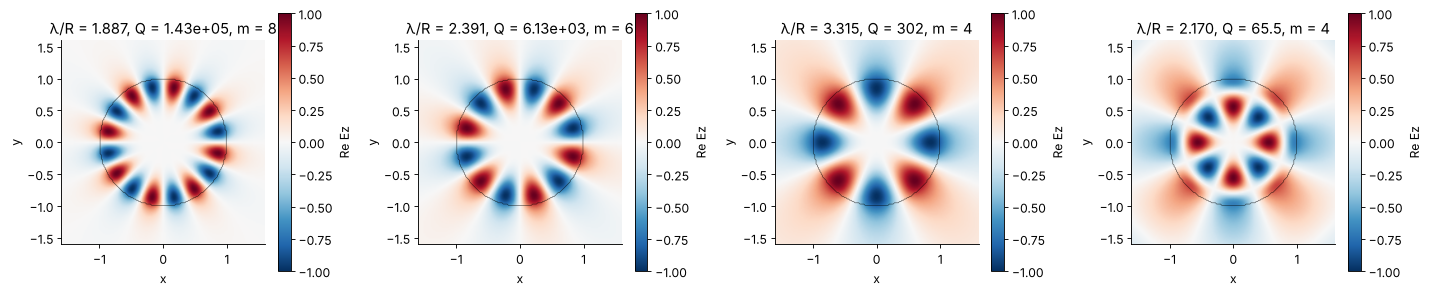

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
picks = sorted([r for r in found["Ez"] if r.Q > 50], key=lambda r: -r.Q)
show = [picks[0], picks[len(picks)//3], picks[2*len(picks)//3], picks[-1]]
for ax, r in zip(axes, show):
    mm, c = fdfd.circle_harmonics(r.field, 0.9*R)
    m_r = abs(mm[np.argmax(np.abs(c))])
    fplot.plot_field(r.field, "Ez", ax=ax, sim=disk, part="real",
                     title=f"λ/R = {r.wavelength:.3f}, Q = {r.Q:.3g}, m = {m_r}")
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
plt.tight_layout()

Convergence of the WGM m = 8 (Ez) with the cell size, wavelength and Q
against the exact mode:

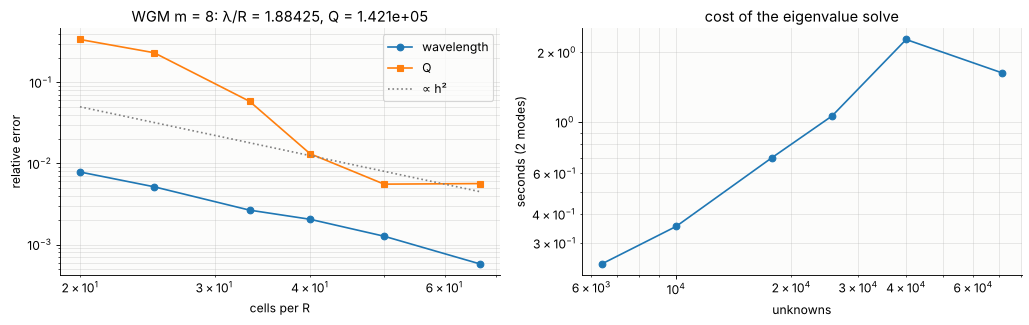

In [7]:
k8 = an.disk_resonance(8, R, n_d, 1.9)
wl8, Q8 = 2*np.pi/k8.real, k8.real/(-2*k8.imag)
hs = np.array([0.05, 0.04, 0.03, 0.025, 0.02, 0.015])
rows = []
for h in hs:
    s = fdfd.Simulation(fdtd.Grid((4.0, 4.0), h), disk.structure)
    t1 = time.perf_counter()
    r = s.resonances(wl8, n=2)[0]
    rows.append((r.wavelength, r.Q, time.perf_counter() - t1))
rows = np.array(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].loglog(1/hs, np.abs(rows[:, 0]/wl8 - 1), "o-", label="wavelength")
axes[0].loglog(1/hs, np.abs(rows[:, 1]/Q8 - 1), "s-", label="Q")
axes[0].loglog(1/hs, 0.05*(hs/0.05)**2, ":", color="gray", label="∝ h²")
axes[0].set_xlabel("cells per R"); axes[0].set_ylabel("relative error"); axes[0].legend()
axes[0].grid(alpha=0.3, which="both"); axes[0].set_title(f"WGM m = 8: λ/R = {wl8:.5f}, Q = {Q8:.4g}")
axes[1].loglog((4/hs)**2, rows[:, 2], "o-")
axes[1].set_xlabel("unknowns"); axes[1].set_ylabel("seconds (2 modes)"); axes[1].grid(alpha=0.3, which="both")
axes[1].set_title("cost of the eigenvalue solve")
plt.tight_layout()

## 4. Far fields

Outside a circle that contains everything, the field is a sum of
outgoing cylindrical waves $a_m H_m(kr)\,e^{im\varphi}$; their
coefficients follow from the field on the circle by an FFT, and the
far-field amplitude is $F(\varphi) = \sum_m a_m (-i)^m e^{im\varphi}$
(`fdfd.farfield`). Checks: a line source radiates the same in all
directions, and a WGM that is a standing wave $\cos(m\varphi)$ radiates
as $\cos^2(m\varphi)$. The sources and the circle of the expansion
(dashed) are drawn with the structures. The WGM is m = 5 (Q ≈ 1300);
for a mode with much higher Q the light it radiates is so weak that the
little the staircase of the grid scatters into other harmonics shows in
the pattern.

line source: intensity 0.9987 … 1.0013; WGM: max. deviation from cos² 0.020


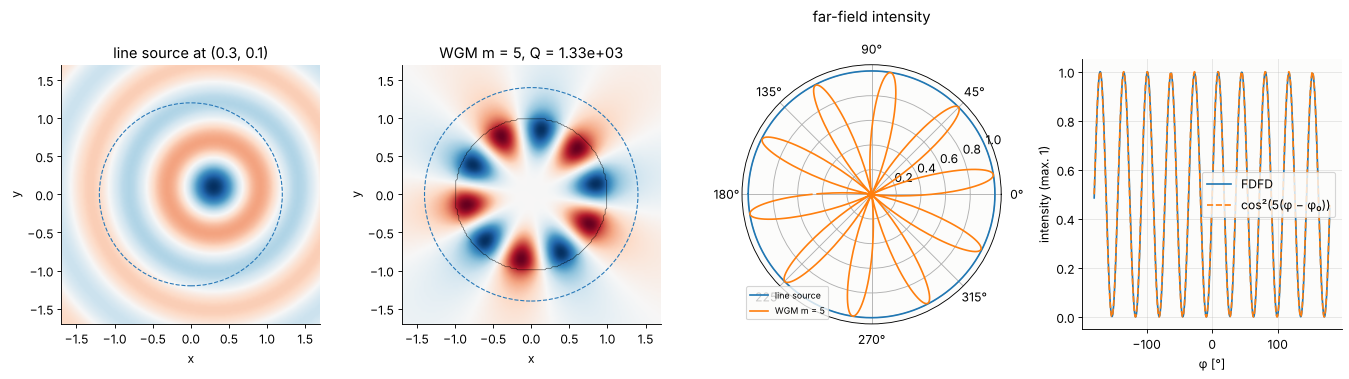

In [8]:
fig = plt.figure(figsize=(17, 4.6))
ax0 = fig.add_subplot(1, 4, 1)
s_free = fdfd.Simulation(fdtd.Grid((4.0, 4.0), 0.02))
sol_free = s_free.solve(1.0, fdfd.PointSource((0.3, 0.1)))
fplot.plot_field(sol_free, "Ez", ax=ax0, sim=s_free, part="real", colorbar=False, title="line source at (0.3, 0.1)")
ax0.add_patch(plt.Circle((0, 0), 1.2, fill=False, ls="--", color="#2a7ab9"))
ax1 = fig.add_subplot(1, 4, 2)
k5 = an.disk_resonance(5, R, n_d, 2.8)
wgm = disk.resonances(2*np.pi/k5.real, n=2)[0]
u = wgm.field.main
x, y = wgm.field.coords["Ez"]
fplot.plot_field(wgm.field, "Ez", ax=ax1, sim=disk, part="real", colorbar=False, title=f"WGM m = 5, Q = {wgm.Q:.3g}")
ax1.add_patch(plt.Circle((0, 0), 1.4, fill=False, ls="--", color="#2a7ab9"))
for ax in (ax0, ax1):
    ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.7, 1.7)

ff_free = fdfd.farfield(sol_free, 1.2)
ff_wgm = fdfd.farfield(wgm.field, 1.4)
ax2 = fig.add_subplot(1, 4, 3, projection="polar")
ax2.plot(ff_free.phi, ff_free.intensity, label="line source")
ax2.plot(ff_wgm.phi, ff_wgm.intensity/ff_wgm.intensity.max(), label="WGM m = 5")
ax2.set_title("far-field intensity", pad=18); ax2.legend(loc="lower left", fontsize=8)
ax3 = fig.add_subplot(1, 4, 4)
m_fit = 5
phi0 = ff_wgm.phi[np.argmax(ff_wgm.intensity)]
model = np.cos(m_fit*(ff_wgm.phi - phi0))**2
ax3.plot(np.degrees(ff_wgm.phi), ff_wgm.intensity/ff_wgm.intensity.max(), label="FDFD")
ax3.plot(np.degrees(ff_wgm.phi), model, "--", label="cos²(5(φ − φ₀))")
ax3.set_xlabel("φ [°]"); ax3.set_ylabel("intensity (max. 1)"); ax3.legend(); ax3.grid(alpha=0.3)
print(f"line source: intensity {ff_free.intensity.min():.4f} … {ff_free.intensity.max():.4f}; "
      f"WGM: max. deviation from cos² {np.abs(ff_wgm.intensity/ff_wgm.intensity.max() - model).max():.3f}")
plt.tight_layout()

## Summary

* `fdfd.Simulation` takes the grid, shapes, media and boundaries of the
  FDTD. `solve()` gives the fields of point sources and plane waves (one
  sparse LU), `resonances()` the quasi-normal modes near a wavelength,
  `resonance(like=...)` follows one mode while the structure changes.
* Against exact series: scattering by a cylinder converges as h² in both
  polarizations; microdisk resonances match in wavelength to about
  10⁻³ and in Q to about 1 % (Ez; a few % in Hz) at 50 cells per
  radius.
* `farfield()` expands the field on a circle into outgoing cylindrical
  waves; `circle_harmonics()` gives the azimuthal numbers of modes.

Next: [67](67_fdfd_limacon_microcavity.ipynb), a whispering gallery
mode followed from the circle into the limaçon of Pascal, and its
emission becoming directional.

In [9]:
print(f"total run time of the notebook: {time.perf_counter() - t_start:.0f} s")

total run time of the notebook: 42 s
